# 01. Análise dos dados crus da v2

O que os anexos da v2 e a Folha-verdade mostram antes de construir o sistema. O que se vê aqui decide o desenho: quais sinais usar, quanto confiar na Origem, o que fazer com os Temas duplicados e qual critério de limiar é viável com 100 rótulos (ADR 0008).

Lê os anexos com as mesmas funções da entrega (`src/classificacao`) e não chama nenhum modelo. Para rodar de novo: `uv sync --group analise` e `uv run jupyter nbconvert --execute --inplace notebooks/01_analise_dos_dados.ipynb`.

In [1]:
import csv
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from classificacao.nucleo.adaptadores.anexos import ler_arvore, ler_folha_verdade, ler_questoes
from classificacao.nucleo.dominio.calibracao import intervalo_de_wilson
from classificacao.nucleo.dominio.regua import certo_pela_regua
from classificacao.v2.adaptadores.dicionarios import ler_leis
from classificacao.v2.dominio.leis import leis_citadas
from classificacao.v2.dominio.origem import disciplina_da_origem, no_da_origem
from classificacao.v2.dominio.textos import texto_da_questao

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
ZIP = RAIZ / "anexos/v2/anexos-case-ia.zip"
arvore = ler_arvore(ZIP)
questoes = ler_questoes(ZIP)
folha = ler_folha_verdade(ZIP)
leis = ler_leis(RAIZ / "dados/v2/leis.csv")
antiga = lambda q: int(q.id[1:]) <= 359
print(
    len(questoes),
    "Questões;",
    len(folha),
    "na Folha-verdade;",
    len(arvore.nos_que_podem_receber_questao()),
    "Nós podem receber Questão",
)

659 Questões; 100 na Folha-verdade; 371 Nós podem receber Questão


## 1. Questões antigas (Q0001–Q0359) e novas (Q0360–Q0659)

As 100 da Folha-verdade são todas antigas. As 300 novas, de concursos recentes, só aparecem na avaliação, então qualquer diferença entre os dois grupos é um risco para a previsão.

In [2]:
linhas = []
for q in questoes:
    linhas.append(
        {
            "grupo": "antiga" if antiga(q) else "nova",
            "disciplina_origem": q.disciplina_origem or "(vazia)",
            "no_recorte": disciplina_da_origem(q.disciplina_origem) is not None,
            "cita_lei": bool(leis_citadas(texto_da_questao(q), leis)),
            "origem_vira_no": no_da_origem(arvore, q.disciplina_origem, q.assunto_origem)
            is not None,
            "tamanho": len(texto_da_questao(q)),
        }
    )
df = pd.DataFrame(linhas)
df.groupby("grupo")[["no_recorte", "cita_lei", "origem_vira_no"]].mean().round(3)

,no_recorte,cita_lei,origem_vira_no
grupo,,,
antiga,0.978,0.362,0.593
nova,0.967,0.450,0.190


In [3]:
pd.crosstab(df.disciplina_origem, df.grupo).sort_values("nova", ascending=False)

grupo,antiga,nova
disciplina_origem,,
Direito Penal,129,150
Processo Penal,131,115
Criminologia,31,25
Direito Penal Militar,0,5
Direito Processual Penal Militar,0,5
(vazia),1,0
Direito Ambiental,1,0
Direito Civil - Legislação Especial,2,0
Direito Constitucional,2,0


**Mudança de distribuição.** A Origem vira um Nó em 59% das antigas e só em 19% das novas, e nenhuma nova vem com a origem "Direito Penal - Legislação Especial". O Ranqueador aprende a confiar na Origem com as antigas e vai encontrá-la bem menos nas novas. A previsão leva isso em conta (ticket 09).

Nas novas, a disciplina de origem inclui Direito Penal Militar e Processual Penal Militar, que a árvore não tem. Esse é o sinal mais claro de Fora, e ele não aparece na Folha-verdade.

## 2. A Folha-verdade

Quantos Nós ela cobre, em que nível, com quantos Extras e quantos Fora.

In [4]:
centrais = [g.tema_central_id for g in folha.values() if g.tema_central_id]
print("Fora:", sum(g.fora for g in folha.values()))
print("Com Extras:", sum(bool(g.extras) for g in folha.values()))
print("Nível do Tema central:", Counter(arvore.no(i).nivel for i in centrais))
print(
    "Nós distintos usados:", len(set(centrais)), "de", len(arvore.nos_que_podem_receber_questao())
)
pd.Series(Counter(arvore.no(i).caminho.split(" > ")[0] for i in centrais)).sort_values(
    ascending=False
)

Fora: 8
Com Extras: 39
Nível do Tema central: Counter({1: 53, 2: 39})
Nós distintos usados: 61 de 371


Penal                                  40
Processo Penal                         30
Direito Penal - Legislação Especial    12
Criminologia                           10
dtype: int64

61 Nós distintos para 371 possíveis: **a maioria dos Temas não tem nenhum exemplo**. O kNN na Folha-verdade ensina a convenção onde há exemplos, mas a decisão nos outros Temas depende da similaridade com o Tema enriquecido e das leis citadas.

## 3. Temas duplicados: de que lado a equipe põe

In [5]:
for qid, g in sorted(folha.items()):
    for no in (g.tema_central_id, *g.extras):
        if no and arvore.em_tema_duplicado(no):
            print(qid, "central" if no == g.tema_central_id else "extra ", arvore.no(no).caminho)

Q0052 central Direito Penal - Legislação Especial > Lei de Execução Penal
Q0061 central Direito Penal - Legislação Especial > Lei de Execução Penal
Q0091 central Direito Penal - Legislação Especial > Lei de Execução Penal
Q0138 central Processo Penal > Lei de Execução Penal
Q0150 central Direito Penal - Legislação Especial > Tráfico de Drogas
Q0240 extra  Processo Penal > Ação Penal > Denúncia
Q0324 central Direito Penal - Legislação Especial > Lei de Execução Penal
Q0324 extra  Processo Penal > Lei de Execução Penal
Q0325 central Processo Penal > Ação Penal > Denúncia
Q0325 extra  Direito Penal - Legislação Especial > Lei Maria da Penha


A equipe usa a Lei de Execução Penal **dos dois lados** (Legislação Especial e Processo Penal). A convenção existe, mas não é absoluta. Por isso o lado entra como sinal aprendido (voto das vizinhas), e não como regra fixa.

## 4. A Origem é confiável?

In [6]:
bate = total = 0
for qid, g in folha.items():
    if g.tema_central_id is None:
        continue
    q = next(q for q in questoes if q.id == qid)
    no = no_da_origem(arvore, q.disciplina_origem, q.assunto_origem)
    total += 1
    bate += no is not None and certo_pela_regua(arvore, no, g)
print(f"A Origem aponta um Nó certo pela Régua em {bate} de {total} Questões dentro da árvore")

A Origem aponta um Nó certo pela Régua em 22 de 92 Questões dentro da árvore


A Origem acerta pouco. Ela entra no Ranqueador como um sinal entre vários, para ele aprender quanto confiar nela. Nunca como regra.

## 5. Leis citadas

In [7]:
por_lei = {lei.numero: lei for lei in leis}
acertos = total = 0
for qid, g in folha.items():
    q = next(q for q in questoes if q.id == qid)
    nos = [
        n
        for numero in leis_citadas(texto_da_questao(q), leis)
        if numero in por_lei
        for n in por_lei[numero].nos
    ]
    if nos:
        total += 1
        acertos += any(certo_pela_regua(arvore, n, g) for n in nos)
print(
    f"Questões que citam alguma lei ou código: {sum(df.cita_lei)} de {len(df)}; na Folha-verdade, entre as que citam lei com Nó, a lei aponta o Ramo certo em {acertos} de {total}"
)

Questões que citam alguma lei ou código: 265 de 659; na Folha-verdade, entre as que citam lei com Nó, a lei aponta o Ramo certo em 9 de 13


## 6. Quantos rótulos a Régua exigiria com garantia estatística (ADR 0008)

Para publicar com 95% de confiança de cumprir a Régua, o limite inferior de Wilson das publicadas precisa passar de 0,95.

In [8]:
def acertos_necessarios(erros):
    n = erros + 1
    while intervalo_de_wilson(n - erros, n)[0] < 0.95:
        n += 1
    return n - erros


tabela = pd.DataFrame(
    {"erros": range(4), "acertos_necessarios": [acertos_necessarios(e) for e in range(4)]}
)
tabela

,erros,acertos_necessarios
0,0,73
1,1,109
2,2,140
3,3,170


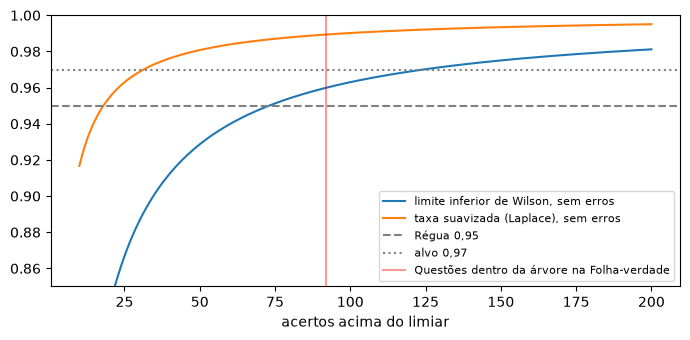

In [9]:
n = range(10, 201)
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(n, [intervalo_de_wilson(k, k)[0] for k in n], label="limite inferior de Wilson, sem erros")
ax.plot(n, [(k + 1) / (k + 2) for k in n], label="taxa suavizada (Laplace), sem erros")
ax.axhline(0.95, color="gray", linestyle="--", label="Régua 0,95")
ax.axhline(0.97, color="gray", linestyle=":", label="alvo 0,97")
ax.axvline(92, color="red", alpha=0.4, label="Questões dentro da árvore na Folha-verdade")
ax.set_xlabel("acertos acima do limiar")
ax.set_ylim(0.85, 1.0)
ax.legend(fontsize=8)
plt.tight_layout()

Com 92 Questões dentro da árvore, exigir o limite inferior ≥ 0,95 obrigaria a publicar quase todas sem nenhum erro. Por isso o limiar usa a **taxa suavizada ≥ 0,97**: a margem sobre a Régua substitui uma garantia que 100 rótulos não dão (ADR 0008).

## 7. Como a v1 se sai na Folha-verdade

A entrega v1 (dois LLMs votando) foi feita antes da Folha-verdade existir. Medida contra ela pela Régua da v2:

In [10]:
with (RAIZ / "entregas/v1/publicacao.csv").open(newline="") as f:
    v1 = {l["id"]: l for l in csv.DictReader(f)}
publicadas = [
    (qid, int(v1[qid]["tema_central_id"])) for qid in folha if v1[qid]["decisao"] == "publicar"
]
certas = [qid for qid, no in publicadas if certo_pela_regua(arvore, no, folha[qid])]
print(
    f"v1: {len(certas)} de {len(publicadas)} publicadas certas = {len(certas) / len(publicadas):.2f} (previsão era 0,97)"
)
for qid, no in publicadas:
    if qid not in certas:
        g = folha[qid]
        print(
            " ",
            qid,
            "publicou",
            arvore.no(no).caminho,
            "| equipe:",
            "Fora" if g.fora else arvore.no(g.tema_central_id).caminho,
        )

v1: 75 de 83 publicadas certas = 0.90 (previsão era 0,97)
  Q0002 publicou Criminologia > Processos de Criminalização e Cifras Criminais > Criminalização Primária e Secundária | equipe: Fora
  Q0003 publicou Processo Penal > Procedimento Ordinário > Absolvição Sumária | equipe: Processo Penal > Recursos em Espécies
  Q0043 publicou Penal > Teoria da Pena | equipe: Fora
  Q0091 publicou Penal > Teoria da Pena > Penas Privativas de Liberdade | equipe: Direito Penal - Legislação Especial > Lei de Execução Penal
  Q0252 publicou Penal > Teoria da Pena > Pena de Multa | equipe: Fora
  Q0259 publicou Penal > Lei Penal no Tempo e no Espaço > Conflito Aparente de Normas | equipe: Penal > Introdução ao Estudo do Direito Penal > Princípios do Direito Penal
  Q0303 publicou Penal > Lei Penal no Tempo e no Espaço | equipe: Fora
  Q0324 publicou Penal > Teoria da Pena | equipe: Direito Penal - Legislação Especial > Lei de Execução Penal


A v1 ficou em 0,90, abaixo da Régua. Metade dos erros são Questões que a equipe considera **Fora**, e dois são execução penal que a equipe põe na LEP. São convenções da equipe que só os exemplos ensinam. É isso que a v2 aprende com a Folha-verdade.